## Load Study Data

In [1]:
##imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import sys

%matplotlib inline
from matplotlib import pyplot as plt
sys.path.append(os.path.join(os.getcwd(), '..'))

from datetime import datetime, timedelta
import importlib
from tqdm import tqdm


from babelbetes.studies.studydataset import StudyDataset
from babelbetes import drawing, cdf, tdd, logger, pandas_helper,data_store

import logging
logger = logger.Logger.get_logger("",logging.WARNING)


C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100',
         magenta='#e87ba4', green='#008300', violet='#4a3aa7', red='#e34948')
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8983', '#e6e5e1'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'font.size': 10,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.titlecolor': INK, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'grid.color': GRID,
    'figure.dpi': 150, 'axes.prop_cycle': plt.cycler(color=list(C.values())),
})
%matplotlib inline

In [2]:
from babelbetes import data_store
from babelbetes.survey import compute
import pandas as pd

# Scope to one study, or filter further to one patient
STORE_BASE_PATH = os.path.join(os.getcwd(),'..','data/out')
store = data_store.load(STORE_BASE_PATH, studies=["ReplaceBG","Flair","DCLP5"])
print(store.keys())

dict_keys(['cgm', 'bolus', 'basal', 'age', 'carbs'])


## TDD

In [3]:
df_bolus = store['bolus']
df_tdd = df_bolus.groupby(["study_name", "patient_id"]).apply(lambda df: tdd.calculate_daily_bolus_dose(df))

/var/folders/m4/5d02b2xs0l52lbxzbk0t3vym0000gp/T/ipykernel_31273/2455411244.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_tdd = df_bolus.groupby(["study_name", "patient_id"]).apply(lambda df: tdd.calculate_daily_bolus_dose(df))


In [4]:
from scipy.stats import gmean, gstd
minmultiple = lambda x: x.median()/ x.min()
maxmultiple = lambda x: x.max() / x.median()

df_tdd_patient = df_tdd.groupby(['study_name', 'patient_id']).bolus.agg(
    median='median',
    gmean=gmean,
    gstd=gstd,
    min='min',
    max='max',
    minmultiple=minmultiple,
    maxmultiple=maxmultiple,
)
df_tdd_patient

median      gmean      gstd       min         max  \
study_name patient_id                                                         
DCLP5      1           26.404050  26.344550  1.281925  9.854786   44.999707   
           10          18.527876  17.797538  1.383112  3.894161   34.259766   
           100         13.609431  13.285497  1.360384  5.070000   26.283363   
           101         11.051819  10.460264  1.487996  1.784167   24.058747   
           11           8.351692   8.274991  1.280557  2.334593   14.851860   
...                          ...        ...       ...       ...         ...   
ReplaceBG  93          23.150000  22.955973  1.308067  4.500000   43.850000   
           95          17.150000  16.988814  1.309674  3.150000   33.050000   
           96          17.300000  17.144245  1.310841  6.700000   38.720000   
           97          28.450000  27.995758  1.511939  2.000000   77.200000   
           98          39.650000  39.417153  1.437530  6.400000  107.800000   

                       minmultiple  maxmultiple  
study_name patient_id                            
DCLP5      1              2.679312     1.704273  
           10             4.757861     1.849093  
           100            2.684306     1.931261  
           101            6.194387     2.176904  
           11             3.577366     1.778306  
...                            ...          ...  
ReplaceBG  93             5.144444     1.894168  
           95             5.444444     1.927114  
           96             2.582090     2.238150  
           97            14.225000     2.713533  
           98             6.195313     2.718789  

[411 rows x 7 columns]

Text(56.333333333333336, 0.5, 'maxmultiple max/median')

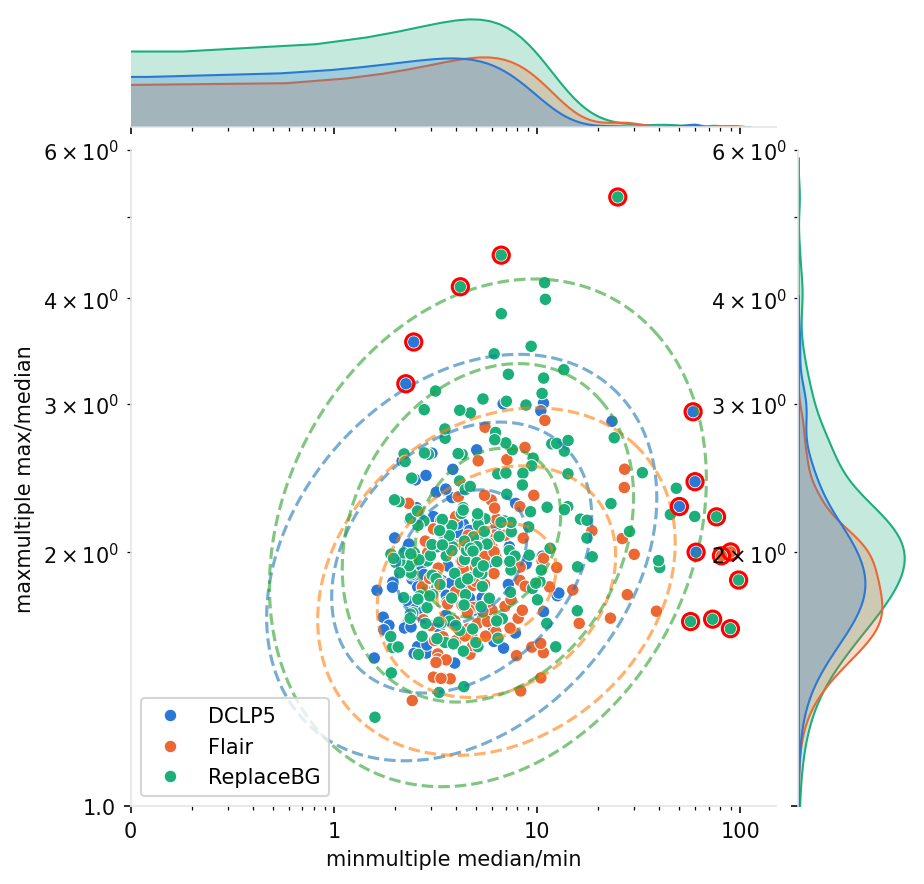

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import ScalarFormatter

def fit_bivariate(x, y, log=True):
    """Fit a bivariate normal (log=False) or lognormal (log=True).
    Returns (mean, cov) in fitting space (log-space if log=True)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    fx, fy = (np.log(x), np.log(y)) if log else (x, y)
    mean = np.array([fx.mean(), fy.mean()])
    cov = np.cov(fx, fy)
    return mean, cov

def plot_confidence_ellipses(mean, cov, ax, n_stds=(1, 2, 3), log=True,
                              n_points=200, **kwargs):
    """Draw concentric 'n standard deviations away' contours from (mean, cov).
    If log=True, ellipses are built in log-space then mapped back through
    exp(), so they appear curved (not true ellipses) in original units.
    Auto-expands ax's x/y limits so the full contours stay visible."""
    mean_x, mean_y = mean
    std_x, std_y = np.sqrt(np.diag(cov))
    r = cov[0, 1] / (std_x * std_y)

    theta = np.linspace(0, 2 * np.pi, n_points)
    circle = np.vstack([np.sqrt(1 + r) * np.cos(theta), np.sqrt(1 - r) * np.sin(theta)])
    rot = np.array([[np.cos(np.pi/4), -np.sin(np.pi/4)],
                     [np.sin(np.pi/4),  np.cos(np.pi/4)]])
    circle = rot @ circle

    defaults = dict(alpha=0.6, color="black", linestyle="--")
    defaults.update(kwargs)

    lines = []
    for n_std in n_stds:
        ex = circle[0] * std_x * n_std + mean_x
        ey = circle[1] * std_y * n_std + mean_y
        if log:
            ex, ey = np.exp(ex), np.exp(ey)
        line, = ax.plot(ex, ey, **defaults)
        lines.append(line)

    ax.relim()
    ax.autoscale_view()
    return lines

def find_outliers(x, y, mean, cov, log=True, n_std=3):
    """Flag points > n_std Mahalanobis distance from the fit.

    Mahalanobis distance = "how many std devs away", corrected for the
    data's shape: cov describes the spread/correlation ellipse of the
    data, and multiplying by inv(cov) rescales distance to match it -
    shrinking distance along naturally spread-out/correlated directions
    (expected, not penalized) and stretching it elsewhere (surprising).
    Plain Euclidean distance would wrongly assume the data is circular.
    """
    x, y = np.asarray(x, float), np.asarray(y, float)
    fx, fy = (np.log(x), np.log(y)) if log else (x, y)
    d = np.column_stack([fx - mean[0], fy - mean[1]])
    inv_cov = np.linalg.inv(cov)
    # per-point quadratic form d_i @ inv_cov @ d_i, vectorized over all i
    dist = np.sqrt(np.einsum("ij,jk,ik->i", d, inv_cov, d))
    return dist > n_std, dist

def highlight_outliers(x, y, mean, cov, ax, log=True, n_std=3, **kwargs):
    """Overlay a red edge ring on points flagged as outliers (> n_std)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask, dist = find_outliers(x, y, mean, cov, log=log, n_std=n_std)
    defaults = dict(facecolors="none", edgecolors="red", linewidths=1.5, s=60, zorder=5)
    defaults.update(kwargs)
    ax.scatter(x[mask], y[mask], **defaults)
    return mask, dist


colors = dict(zip(df_tdd_patient.index.get_level_values('study_name').unique(), plt.cm.tab10.colors))

#fit
fits = df_tdd_patient.groupby(['study_name']).apply(lambda df: fit_bivariate(df.minmultiple, df.maxmultiple))
fits = pd.DataFrame(fits.tolist(), index=fits.index, columns=['mean', 'cov'])

#draw
jointplot = sns.jointplot(df_tdd_patient, x='minmultiple', y='maxmultiple', hue='study_name', kind='scatter')
ax = jointplot.ax_joint

fits.apply(lambda row: plot_confidence_ellipses(row['mean'], row['cov'], ax=ax, 
                                                color=colors[row.name]
                                                ), axis=1)

for study, grp in df_tdd_patient.groupby('study_name'):
    mean, cov = fits.loc[study, 'mean'], fits.loc[study, 'cov']
    highlight_outliers(grp['minmultiple'], grp['maxmultiple'], mean, cov, ax=ax)

ax.legend(loc='lower left')
ax.set_xscale('log')
ax.set_yscale('log')
formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_powerlimits((4,100))

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.set_xlim(0.1,150)
ax.set_ylim(1,6)

ax.set_xlabel('minmultiple median/min')
ax.set_ylabel('maxmultiple max/median')

In [ ]:
df_tdd_patient.minmultiple.min()

1.5812882942073407

Text(56.333333333333336, 0.5, '$\\sigma*$')

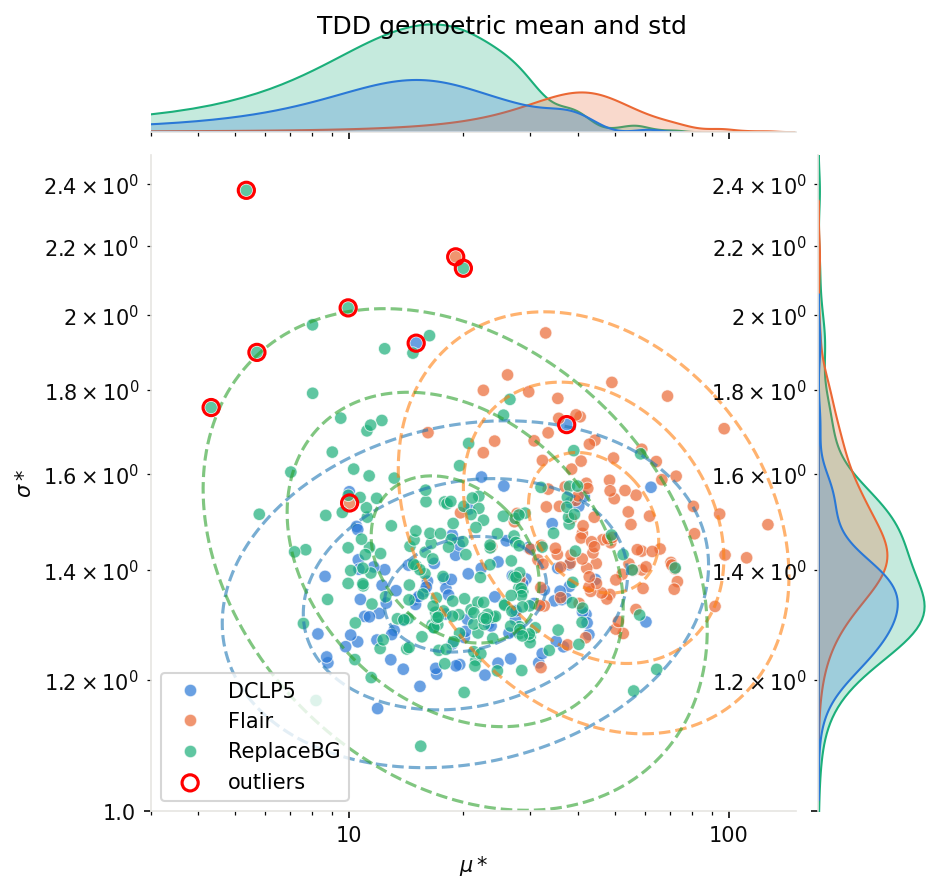

In [19]:
colors = dict(zip(df_tdd_patient.index.get_level_values('study_name').unique(), plt.cm.tab10.colors))

#fit
x = 'gmean'
y='gstd'

fits = df_tdd_patient.groupby(['study_name']).apply(lambda df: fit_bivariate(df[x], df[y]))
fits = pd.DataFrame(fits.tolist(), index=fits.index, columns=['mean', 'cov'])

#draw
jointplot = sns.jointplot(df_tdd_patient, x=x, y=y, hue='study_name', kind='scatter', alpha=0.7)
ax = jointplot.ax_joint
axtop = jointplot.ax_marg_x
fits.apply(lambda row: plot_confidence_ellipses(row['mean'], row['cov'], ax=ax, color=colors[row.name]), axis=1)

for i,(study, grp) in enumerate(df_tdd_patient.groupby('study_name')):
    mean, cov = fits.loc[study, 'mean'], fits.loc[study, 'cov']
    highlight_outliers(grp[x], grp[y], mean, cov, ax=ax,label='outliers' if i==1 else '')

ax.legend(loc='lower left')
ax.set_xscale('log')
ax.set_yscale('log')
formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_powerlimits((4,100))

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.set_xlim(3,150)
ax.set_ylim(1,2.5)
plt.suptitle("TDD gemoetric mean and std")
ax.set_xlabel(r"$\mu*$")
ax.set_ylabel(r"$\sigma*$")


## Data Completeness

1. Span efficiency = core_span / union_span
where core = [max(first_g, first_b, first_i), min(last_g, last_b, last_i)] and union = [min of firsts, max of lasts], in days.
Catches all overhang in one number. 1.0 = the three streams start and stop together. 0.6 = 40% of the patient's total record is not covered by all three. Use the ratio this way round, not union/core — it's bounded, so degenerate patients (core span near zero, or negative → clamp to 0) land at 0 instead of infinity and don't wreck the cohort distribution.
2. Core completeness = days where all three available inside core / core_span days
Catches interior gaps. Independent of #1 by construction: #1 is about edges, #2 about the middle. A patient can be 0.98 / 0.55 (clean edges, shredded interior → import problem) or 0.4 / 1.0 (clipping candidate, data itself is fine). That 2×2 is your triage and it needs no thresholds.
Bonus, free: the product of the two = all-three-days / union_span. That's the single scalar if you want one column to sort by; the two components tell you which direction to zoom.

In [ ]:
grp_keys = ['study_name','patient_id']
df_basal = store['basal']
dt_basal = df_basal.assign(date=df_basal.datetime.dt.date).groupby(grp_keys).date.agg(['min','max']).reset_index().assign(type='basal')
dt_bolus = df_bolus.assign(date=df_bolus.datetime.dt.date).groupby(grp_keys).date.agg(['min','max']).reset_index().assign(type='bolus')

temp = pd.concat([dt_basal,dt_bolus])
temp.groupby(grp_keys).apply(lambda x: x['max'].max()-x['min'].min())

In [373]:
df_cgm = pd.DataFrame(columns=grp_keys+['glucose','datetime'])
df_cgm['datetime']=pd.to_datetime(df_cgm['datetime'])
df_cgm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 0 entries
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   study_name  0 non-null      object        
 1   patient_id  0 non-null      object        
 2   glucose     0 non-null      object        
 3   datetime    0 non-null      datetime64[ns]
dtypes: datetime64[ns](1), object(3)
memory usage: 124.0+ bytes


In [382]:
import pandas as pd

KEYS = ['study_name', 'patient_id']

def day_index(df):
    """Event-Frame -> eindeutige (study, patient, date)-Tripel."""
    return (df[KEYS]
            .assign(date=df['datetime'].dt.floor('D'))
            .drop_duplicates())


days = pd.concat([
    day_index(df_cgm).assign(stream='cgm'),
    day_index(df_bolus).assign(stream='bolus'),
    day_index(df_basal).assign(stream='basal'),
], ignore_index=True)

#display(days.head())
# --- 1. Ränder pro Stream, daraus Core und Union -----------------------------
edges = days.groupby(KEYS + ['stream'])['date'].agg(['min', 'max'])

#display(edges.head())

b = pd.DataFrame({
    'n_streams' : edges.groupby(KEYS).size(),          # muss 3 sein!
    'core_start': edges['min'].groupby(KEYS).max(),
    'core_end'  : edges['max'].groupby(KEYS).min(),
    'uni_start' : edges['min'].groupby(KEYS).min(),
    'uni_end'   : edges['max'].groupby(KEYS).max(),
})

b['core_days']  = ((b.core_end - b.core_start).dt.days + 1).clip(lower=0)
b['union_days'] =  (b.uni_end  - b.uni_start ).dt.days + 1
b['core_ratio']   = b.core_days / b.union_days

#display(b.head())

# Core coverage
present = (days.assign(v=True)
               .set_index(KEYS + ['date', 'stream'])['v']
               .unstack('stream', fill_value=False))
present['all3'] = present.all(axis=1)

p = present.reset_index().merge(b[['core_start', 'core_end']], on=KEYS)
inside = p[(p.date >= p.core_start) & (p.date <= p.core_end)]

b['all3_days']  = inside.groupby(KEYS)['all3'].sum().reindex(b.index).fillna(0)
b['core_compl'] = (b.all3_days / b.core_days).where(b.core_days > 0, 0.0)
df_coverage = b
df_coverage

n_streams core_start   core_end  uni_start    uni_end  \
study_name patient_id                                                          
DCLP5      1                   2 2018-11-15 2019-06-20 2018-06-16 2019-06-21   
           10                  2 2018-11-29 2019-06-20 2018-06-22 2019-06-20   
           100                 2 2019-01-22 2019-08-12 2019-01-22 2019-08-12   
           101                 2 2018-07-09 2019-02-17 2018-03-02 2019-02-17   
           11                  2 2019-07-31 2019-10-26 2019-04-01 2019-10-26   
...                          ...        ...        ...        ...        ...   
ReplaceBG  93                  2 2015-01-01 2015-09-10 2015-01-01 2015-09-10   
           95                  2 2015-01-01 2015-09-10 2015-01-01 2015-09-10   
           96                  2 2015-01-01 2015-07-15 2015-01-01 2015-07-15   
           97                  2 2015-01-01 2015-09-09 2015-01-01 2015-09-10   
           98                  2 2015-03-26 2015-09-17 2015-03-26 2015-09-17   

                       core_days  union_days  core_ratio  all3_days  \
study_name patient_id                                                 
DCLP5      1                 218         371    0.587601        215   
           10                204         364    0.560440        204   
           100               203         203    1.000000        203   
           101               224         353    0.634561        223   
           11                 88         209    0.421053         88   
...                          ...         ...         ...        ...   
ReplaceBG  93                253         253    1.000000        252   
           95                253         253    1.000000        253   
           96                196         196    1.000000        196   
           97                252         253    0.996047        247   
           98                176         176    1.000000        176   

                       core_compl  
study_name patient_id              
DCLP5      1             0.986239  
           10            1.000000  
           100           1.000000  
           101           0.995536  
           11            1.000000  
...                           ...  
ReplaceBG  93            0.996047  
           95            1.000000  
           96            1.000000  
           97            0.980159  
           98            1.000000  

[411 rows x 10 columns]

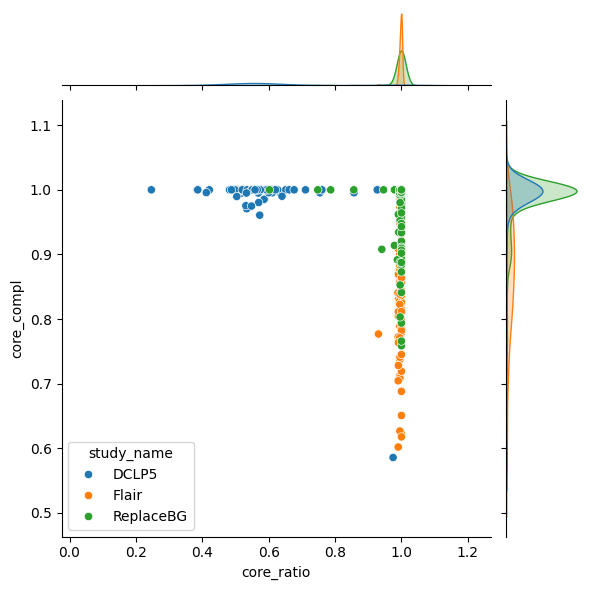

In [ ]:
x= 'core_ratio'; y = 'core_compl'

#draw
jointplot = sns.jointplot(df_coverage, x=x, y=y, hue='study_name', kind='scatter')
ax = jointplot.ax_joint
ax.set_xscale('log')
ax.set_yscale('log')


for study, grp in df_coverage.groupby('study_name'):
    mean, cov = fit_bivariate(grp[x], grp[y])
    #plot_confidence_ellipses(mean, cov, ax=ax, color=colors[study])
    highlight_outliers(grp[x], grp[y], mean, cov, ax=ax)

ax.legend(loc='lower left')
formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_powerlimits((4,100))

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.set_xlim(0.2,1)
# ax.set_ylim(1,6)

##ax.set_xlabel(x)
#ax.set_ylabel(y)